In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = Path.cwd().parents[1]

plt.style.use('seaborn-v0_8-whitegrid')  # Remove this line if using an older matplotlib version
train_raw = pd.read_csv(ROOT / 'data/cleaned_raw_train.csv')
# Sample up to 4,000 points for scatter plots so they render fast and stay clean
sample_df = train_raw.sample(min(4000, len(train_raw)), random_state=42).copy()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']


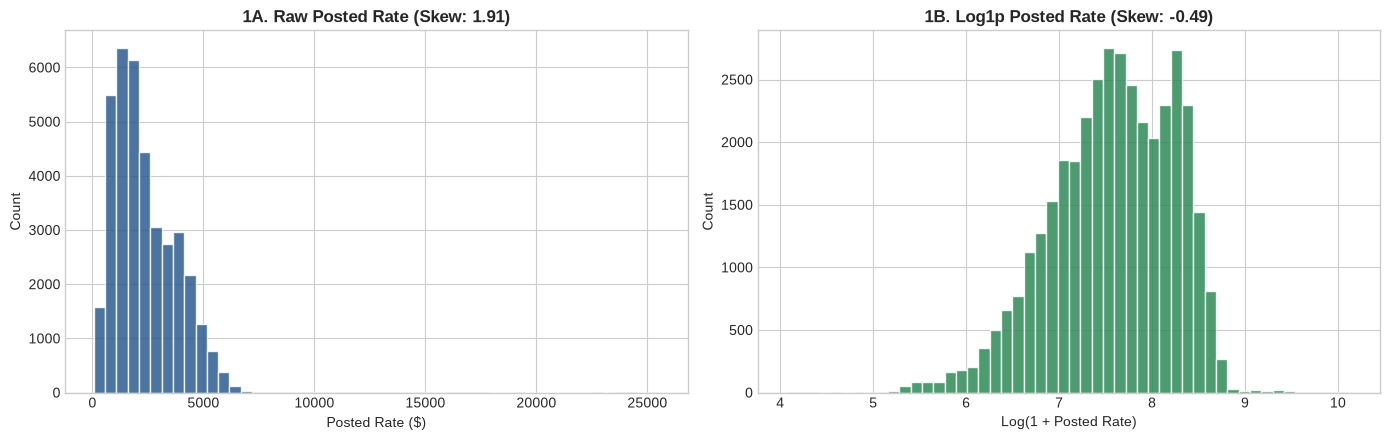

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Raw target
axes[0].hist(train_raw['posted_rate'], bins=50, color='#2b5c8f', edgecolor='white', alpha=0.85)
axes[0].set_title(f"1A. Raw Posted Rate (Skew: {train_raw['posted_rate'].skew():.2f})", fontweight='bold')
axes[0].set_xlabel("Posted Rate ($)")
axes[0].set_ylabel("Count")

# Log1p target
log_rate = np.log1p(train_raw['posted_rate'])
axes[1].hist(log_rate, bins=50, color='#2e8b57', edgecolor='white', alpha=0.85)
axes[1].set_title(f"1B. Log1p Posted Rate (Skew: {log_rate.skew():.2f})", fontweight='bold')
axes[1].set_xlabel("Log(1 + Posted Rate)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


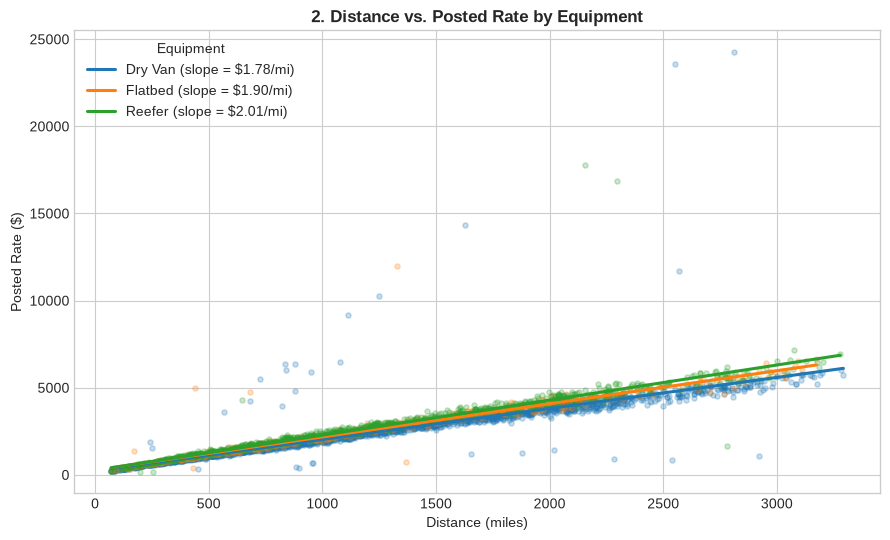

In [41]:
plt.figure(figsize=(9, 5.5))

for idx, (eq, grp) in enumerate(sample_df.groupby('equipment')):
    c = colors[idx % len(colors)]
    plt.scatter(grp['distance'], grp['posted_rate'], alpha=0.25, s=14, color=c)
    
    m, b = np.polyfit(grp['distance'], grp['posted_rate'], 1)
    x_vals = np.linspace(grp['distance'].min(), grp['distance'].max(), 100)
    plt.plot(x_vals, m * x_vals + b, color=c, linewidth=2.2, label=f"{eq} (slope = ${m:.2f}/mi)")

plt.title("2. Distance vs. Posted Rate by Equipment", fontweight='bold')
plt.xlabel("Distance (miles)")
plt.ylabel("Posted Rate ($)")
plt.legend(title="Equipment")
plt.tight_layout()
plt.show()


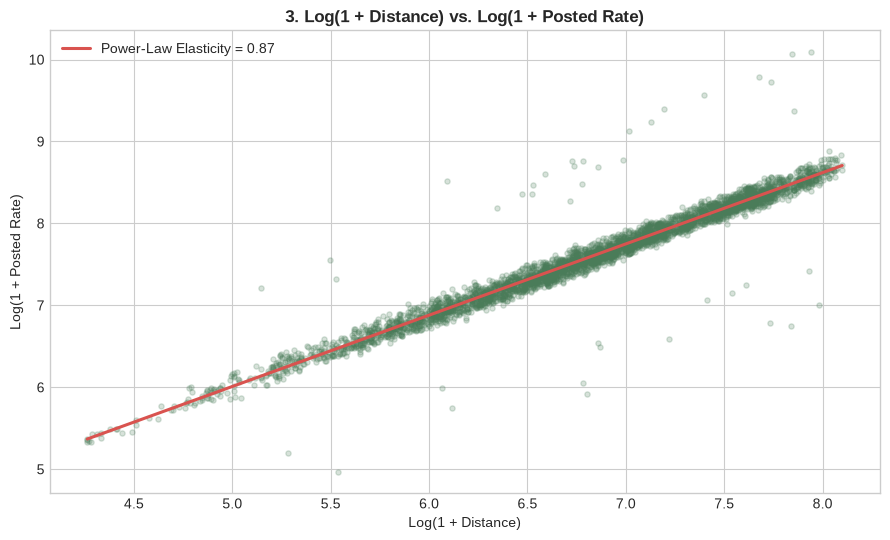

In [42]:
plt.figure(figsize=(9, 5.5))

log_dist_sample = np.log1p(sample_df['distance'])
log_rate_sample = np.log1p(sample_df['posted_rate'])

plt.scatter(log_dist_sample, log_rate_sample, alpha=0.22, s=14, color='#4a7c59')

m_log, b_log = np.polyfit(log_dist_sample, log_rate_sample, 1)
x_log_vals = np.linspace(log_dist_sample.min(), log_dist_sample.max(), 100)
plt.plot(x_log_vals, m_log * x_log_vals + b_log, color='#d9534f', linewidth=2.2,
         label=f"Power-Law Elasticity = {m_log:.2f}")

plt.title("3. Log(1 + Distance) vs. Log(1 + Posted Rate)", fontweight='bold')
plt.xlabel("Log(1 + Distance)")
plt.ylabel("Log(1 + Posted Rate)")
plt.legend()
plt.tight_layout()
plt.show()


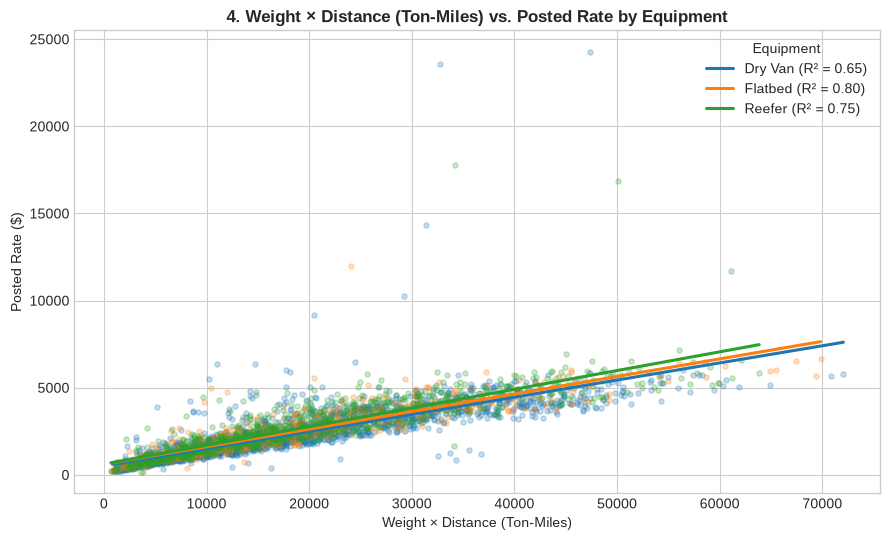

In [43]:
plt.figure(figsize=(9, 5.5))

# Convert to ton-miles (weight in tons * distance) so x-axis numbers stay clean
sample_df['ton_miles'] = (sample_df['weight'] / 2000.0) * sample_df['distance']

for idx, (eq, grp) in enumerate(sample_df.groupby('equipment')):
    c = colors[idx % len(colors)]
    plt.scatter(grp['ton_miles'], grp['posted_rate'], alpha=0.25, s=14, color=c)
    
    m, b = np.polyfit(grp['ton_miles'], grp['posted_rate'], 1)
    r2 = np.corrcoef(grp['ton_miles'], grp['posted_rate'])[0, 1] ** 2
    x_vals = np.linspace(grp['ton_miles'].min(), grp['ton_miles'].max(), 100)
    plt.plot(x_vals, m * x_vals + b, color=c, linewidth=2.2,
             label=f"{eq} (R² = {r2:.2f})")

plt.title("4. Weight × Distance (Ton-Miles) vs. Posted Rate by Equipment", fontweight='bold')
plt.xlabel("Weight × Distance (Ton-Miles)")
plt.ylabel("Posted Rate ($)")
plt.legend(title="Equipment")
plt.tight_layout()
plt.show()


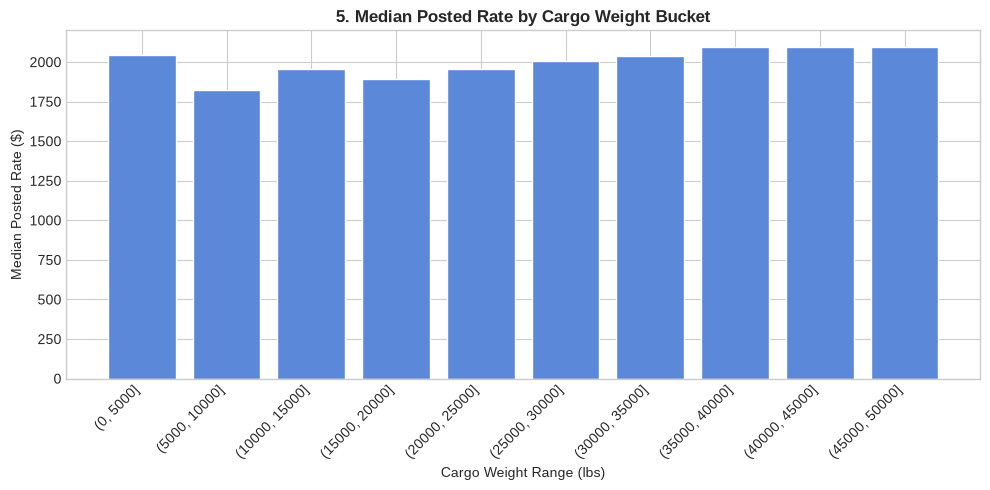

In [44]:
plt.figure(figsize=(10, 5))

train_temp = train_raw.copy()
max_w = int(train_temp['weight'].max())
train_temp['weight_bin'] = pd.cut(train_temp['weight'], bins=range(0, max_w + 5000, 5000))
weight_summary = train_temp.groupby('weight_bin', observed=True)['posted_rate'].median()

plt.bar(range(len(weight_summary)), weight_summary.values, color='#5c88da', edgecolor='white')
plt.xticks(range(len(weight_summary)), [str(idx) for idx in weight_summary.index], rotation=45, ha='right')
plt.title("5. Median Posted Rate by Cargo Weight Bucket", fontweight='bold')
plt.xlabel("Cargo Weight Range (lbs)")
plt.ylabel("Median Posted Rate ($)")
plt.tight_layout()
plt.show()


In [45]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr

# Build candidate features on train_raw only
cand = pd.DataFrame(index=train_raw.index)
cand['distance'] = train_raw['distance']
cand['log_distance'] = np.log1p(train_raw['distance'])
cand['sqrt_distance'] = np.sqrt(train_raw['distance'])
cand['distance_sq'] = train_raw['distance'] ** 2

cand['weight'] = train_raw['weight']
cand['log_weight'] = np.log1p(train_raw['weight'])
cand['is_heavy_40k'] = (train_raw['weight'] > 40000).astype(int)

cand['market_index'] = train_raw['market_index']
cand['log_market_index'] = np.log1p(train_raw['market_index'])

# Interaction terms
cand['dist_x_weight'] = train_raw['distance'] * train_raw['weight']
cand['dist_x_heavy40k'] = train_raw['distance'] * cand['is_heavy_40k']
cand['dist_x_market'] = train_raw['distance'] * train_raw['market_index']
cand['logdist_x_market'] = cand['log_distance'] * train_raw['market_index']

# Targets: Raw vs. Log1p
y_raw = train_raw['posted_rate']
y_log = np.log1p(train_raw['posted_rate'])

# Compute Mutual Information (captures ANY non-linear relationship)
mi_raw = mutual_info_regression(cand, y_raw, random_state=42)

results = []
for idx, col in enumerate(cand.columns):
    r_raw = cand[col].corr(y_raw)
    r_log = cand[col].corr(y_log)
    rho, _ = spearmanr(cand[col], y_raw)
    results.append({
        'Feature': col,
        'Pearson_r (Raw Target)': round(r_raw, 4),
        'R2_Linear (Raw Target)': round(r_raw ** 2, 4),
        'Pearson_r (Log Target)': round(r_log, 4),
        'R2_Linear (Log Target)': round(r_log ** 2, 4),
        'Spearman_rho (Rank)': round(rho, 4),
        'Mutual_Info': round(mi_raw[idx], 4)
    })

metrics_df = pd.DataFrame(results).sort_values('R2_Linear (Log Target)', ascending=False)
print("=== FEATURE & TRANSFORMATION DIAGNOSTIC TABLE ===")
print(metrics_df.to_string(index=False))


=== FEATURE & TRANSFORMATION DIAGNOSTIC TABLE ===
         Feature  Pearson_r (Raw Target)  R2_Linear (Raw Target)  Pearson_r (Log Target)  R2_Linear (Log Target)  Spearman_rho (Rank)  Mutual_Info
    log_distance                  0.8554                  0.7317                  0.9677                  0.9364               0.9760       2.0666
   sqrt_distance                  0.9019                  0.8134                  0.9474                  0.8975               0.9760       2.0670
        distance                  0.9098                  0.8278                  0.8992                  0.8085               0.9760       2.0671
   dist_x_market                  0.8942                  0.7996                  0.8791                  0.7728               0.9654       1.6243
   dist_x_weight                  0.8427                  0.7101                  0.8278                  0.6852               0.9225       1.0707
     distance_sq                  0.8671                  0.7519    

In [46]:
print("\n=== EQUIPMENT-SPECIFIC LINEAR FIT (Rate ~ Distance) ===")
eq_stats = []
for eq, grp in train_raw.groupby('equipment'):
    slope, intercept = np.polyfit(grp['distance'], grp['posted_rate'], 1)
    r_val = grp['distance'].corr(grp['posted_rate'])
    
    # Also check Log-Log fit per equipment
    slope_log, _ = np.polyfit(np.log1p(grp['distance']), np.log1p(grp['posted_rate']), 1)
    r_log_val = np.log1p(grp['distance']).corr(np.log1p(grp['posted_rate']))
    
    eq_stats.append({
        'Equipment': eq,
        'Count': len(grp),
        'Base_Intercept ($)': round(intercept, 2),
        'Slope ($/mile)': round(slope, 3),
        'Raw_R2': round(r_val ** 2, 4),
        'LogLog_Elasticity': round(slope_log, 3),
        'LogLog_R2': round(r_log_val ** 2, 4)
    })

print(pd.DataFrame(eq_stats).to_string(index=False))



=== EQUIPMENT-SPECIFIC LINEAR FIT (Rate ~ Distance) ===
Equipment  Count  Base_Intercept ($)  Slope ($/mile)  Raw_R2  LogLog_Elasticity  LogLog_R2
  Dry Van  21370              252.11           1.771  0.8317              0.873     0.9458
  Flatbed   6816              296.40           1.895  0.8563              0.868     0.9381
   Reefer   9444              282.32           1.998  0.8314              0.874     0.9369


In [47]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Select candidate numeric columns to test for linear model inclusion
vif_cols = ['distance', 'log_distance', 'weight', 'is_heavy_40k', 'market_index', 'dist_x_market']
X_scaled = StandardScaler().fit_transform(cand[vif_cols])

vif_df = pd.DataFrame({
    'Feature': vif_cols,
    'VIF': [round(variance_inflation_factor(X_scaled, i), 2) for i in range(len(vif_cols))]
}).sort_values('VIF', ascending=False)

print("\n=== VARIANCE INFLATION FACTOR (VIF > 10 = High Collinearity) ===")
print(vif_df.to_string(index=False))



=== VARIANCE INFLATION FACTOR (VIF > 10 = High Collinearity) ===
      Feature   VIF
     distance 55.42
dist_x_market 51.97
 log_distance  7.03
 market_index  3.43
 is_heavy_40k  1.70
       weight  1.70


## Feature Engineering & Modeling Decisions (Grounded in EDA Diagnostics)

### 1. Key Takeaways from Statistical Diagnostics
* **Power-Law Pricing Structure (`R² = 0.9364`):** Freight rates follow a diminishing per-mile cost curve due to fixed loading and unloading overhead. Transforming both `posted_rate` and `distance` via `np.log1p()` increases linear explained variance from **0.8278** (raw) to **0.9364** (log-log).
* **Parallel Equipment Elasticity (`~0.87` across all trailers):** Dry Van (`0.873`), Flatbed (`0.868`), and Reefer (`0.874`) share virtually identical log-log distance elasticities while shifting the price tier (`$1.77/mi` vs. `$1.90/mi` vs. `$2.00/mi`). On a log-transformed target, encoding `equipment` cleanly captures this percentage markup without needing noisy slope-interaction terms.
* **Multicollinearity & Noise Control (`VIF < 10`):** Variance Inflation Factor (VIF) testing showed severe collinearity when keeping raw `distance` (`VIF = 55.42`) or `dist_x_market` (`VIF = 51.97`) alongside `log_distance` (`VIF = 7.03`). Additionally, multiplying `weight * distance` degraded linear R² from `0.9364` to `0.6852`, confirming that carriers price primarily by truckload space and mileage rather than per-pound ton-miles.

---

### 2. Column-by-Column Feature Decisions
* **`posted_rate` (Target — Transform via `np.log1p`):** Applied `np.log1p()` during training (and inverted via `np.expm1()` at inference) to remove right-skewness and convert multiplicative equipment and market markups into additive linear relationships.
* **`distance` (Transform to `log_distance`; Drop raw in Linear Models):** Engineered `log_distance = np.log1p(distance)` as the primary predictor (`R² = 0.9364`, `VIF = 7.03`). Dropped raw `distance` from the linear model to eliminate multicollinearity (`VIF = 55.42`), while retaining both `distance` and `log_distance` in tree-based models (LightGBM/CatBoost) since trees are immune to collinearity and benefit from exact mileage splits.
* **`equipment` (Categorical Encoding):** One-hot encoded (`drop_first=True`) for linear regression and passed as a native `category` type for gradient boosted trees to capture the parallel price premium across Dry Van, Flatbed, and Reefer (`Log-Log R² = 0.937–0.946` within each tier).
* **`market_index` (Keep Raw; Drop Interactions):** Kept in its raw form (`VIF = 3.43`) and dropped `dist_x_market` (`VIF = 51.97`) and `logdist_x_market` (`R² = 0.3805`). With a log-transformed target, additive `market_index` naturally acts as a percentage surge multiplier without inflating collinearity.
* **`weight` (Keep Raw; Drop Interactions & Threshold Flags):** Retained raw `weight` (`VIF = 1.70`) to preserve minor load effects, but dropped `dist_x_weight` (`R² = 0.6852`) and `is_heavy_40k` (`R² = 0.0008`, `MI = 0.0022`) as they diluted the distance signal without adding predictive power.
* **`date` (Extract Temporal Features & Drop Raw Timestamp):** Extracted `month`, `day`, and `dayofweek` to capture seasonal freight cycles and end-of-week carrier capacity crunches, then dropped the raw `date` column.
* **`pickup_lat`, `pickup_lon`, `delivery_lat`, `delivery_lon` (Keep Coordinates + Engineer Route Geometry):** Retained all four coordinates to capture regional headhaul vs. backhaul imbalances, and engineered `detour_ratio` (`distance / haversine_miles`), `delta_lat`, and `delta_lon` to account for route windingness and directional lane demand.
* **`quote_signal` (Include with Type-Appropriate Preprocessing):** Retained as a real-time spot market demand indicator—scaled via `StandardScaler` if numeric, or one-hot encoded / treated as categorical if discrete.

---

### 3. Modeling Strategy
* **Baseline (`VIF-Clean Log-Log Ridge`):** Establishes an interpretable, leakage-free linear benchmark using `log_distance`, `market_index`, `weight`, spatial features, temporal features, `quote_signal`, and one-hot encoded `equipment` (`all VIF < 10`).
* **Primary Model (`Log-Target LightGBM`):** Captures the remaining ~6% non-linear variance driven by geographic origin-destination interactions, regional market regimes, and seasonal shifts.


In [48]:
import numpy as np
import pandas as pd

def haversine_miles(lat1, lon1, lat2, lon2):
    """Calculates great-circle distance in miles between two lat/lon points."""
    R = 3958.8
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

def transform_freight_data(df, model_type='linear', target_col='posted_rate'):
    """
    Applies feature transformations independently to train or test splits.
    Assumes date extraction and categorical encoding are already completed.
    
    Parameters:
    - df: Pre-split and pre-encoded DataFrame (train or test)
    - model_type: 'linear' (drops raw distance to prevent VIF > 50) or 'tree' (keeps both)
    - target_col: Name of target column (if present, separates and log1p-transforms it)
    
    Returns:
    - X: Transformed feature DataFrame
    - y_log: Log1p-transformed target Series (or None if target_col not in df)
    """
    X = df.copy()
    
    # 1. Separate & log-transform target if present (invert predictions via np.expm1)
    y_log = None
    if target_col in X.columns:
        y_log = np.log1p(X[target_col])
        X = X.drop(columns=[target_col])
        
    # 2. Power-law distance transformation (R2 = 0.9364)
    if 'distance' in X.columns:
        X['log_distance'] = np.log1p(X['distance'])
        
    # 3. Spatial geometry features from coordinates (if present)
    coord_cols = {'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon'}
    if coord_cols.issubset(X.columns):
        hav_dist = haversine_miles(
            X['pickup_lat'], X['pickup_lon'],
            X['delivery_lat'], X['delivery_lon']
        )
        if 'distance' in X.columns:
            X['detour_ratio'] = X['distance'] / np.maximum(hav_dist, 1.0)
        X['delta_lat'] = X['delivery_lat'] - X['pickup_lat']
        X['delta_lon'] = X['delivery_lon'] - X['pickup_lon']
        
    # 4. Drop raw 'distance' for linear models to eliminate multicollinearity (VIF = 55.42)
    if model_type == 'linear' and 'distance' in X.columns:
        X = X.drop(columns=['distance'])
        
    # 5. Drop leaky column if still present
    if 'rate_per_mile' in X.columns:
        X = X.drop(columns=['rate_per_mile'])
        
    return X, y_log


In [49]:
train_encoded = pd.read_csv(ROOT / 'data/cleaned_train_encoded.csv')
test_encoded = pd.read_csv(ROOT / 'data/cleaned_test_encoded.csv')

# --- For Linear Models (e.g., Ridge Regression) ---
X_train_lin, y_train_log = transform_freight_data(train_encoded, model_type='linear')
X_test_lin,  y_test_log  = transform_freight_data(test_encoded,  model_type='linear')

# --- For Tree Models (e.g., LightGBM, CatBoost, XGBoost) ---
X_train_tree, y_train_log = transform_freight_data(train_encoded, model_type='tree')
X_test_tree,  y_test_log  = transform_freight_data(test_encoded,  model_type='tree')

print("Linear Train Shape:", X_train_lin.shape, "| Linear Test Shape:", X_test_lin.shape)
print("Tree Train Shape:  ", X_train_tree.shape, "| Tree Test Shape:  ", X_test_tree.shape)


Linear Train Shape: (37630, 15) | Linear Test Shape: (9408, 15)
Tree Train Shape:   (37630, 16) | Tree Test Shape:   (9408, 16)


In [50]:
train_encoded.columns

Index(['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance',
       'weight', 'market_index', 'quote_signal', 'posted_rate', 'pickup_day',
       'pickup_month', 'equipment_Flatbed', 'equipment_Reefer'],
      dtype='object')

In [51]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from lightgbm import LGBMRegressor

# Recover original dollar targets for final metric evaluation
y_train_dollars = np.expm1(y_train_log)
y_test_dollars  = np.expm1(y_test_log)

# Helper function to compute dollar-scale metrics consistently
def evaluate_dollar_metrics(y_true_dollars, preds_log, model_name, cv_rmse_log=None):
    preds_dollars = np.expm1(preds_log)
    return {
        'Model': model_name,
        'CV_Log_RMSE': round(cv_rmse_log, 4) if cv_rmse_log is not None else np.nan,
        'Test_RMSE ($)': round(root_mean_squared_error(y_true_dollars, preds_dollars), 2),
        'Test_MAE ($)': round(mean_absolute_error(y_true_dollars, preds_dollars), 2),
        'Test_MAPE (%)': round(mean_absolute_percentage_error(y_true_dollars, preds_dollars) * 100, 2),
        'Test_R2': round(r2_score(y_true_dollars, preds_dollars), 4)
    }

# 5-Fold Expanding Window Cross-Validation (preserves chronological order)
tscv = TimeSeriesSplit(n_splits=5)
results = []

# ==============================================================================
# 1. TUNED LINEAR MODEL: Ridge Regression (uses VIF-clean X_train_lin)
# ==============================================================================
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

ridge_param_grid = {
    'ridge__alpha': [0.1, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0]
}

ridge_search = RandomizedSearchCV(
    estimator=ridge_pipe,
    param_distributions=ridge_param_grid,
    n_iter=12,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=2,
    random_state=42,
    verbose=1
)
ridge_search.fit(X_train_lin, y_train_log)

best_ridge = ridge_search.best_estimator_
ridge_test_preds_log = best_ridge.predict(X_test_lin)
results.append(evaluate_dollar_metrics(
    y_test_dollars, ridge_test_preds_log,
    f"1. Tuned Log-Ridge (alpha={ridge_search.best_params_['ridge__alpha']})",
    cv_rmse_log=-ridge_search.best_score_
))

# ==============================================================================
# 2. TUNED ELASTICNET: L1 + L2 Regularized Linear Model
# ==============================================================================
enet_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('enet', ElasticNet(max_iter=5000, random_state=42))
])

enet_param_grid = {
    'enet__alpha': [0.001, 0.01, 0.05, 0.1, 0.5],
    'enet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

enet_search = RandomizedSearchCV(
    estimator=enet_pipe,
    param_distributions=enet_param_grid,
    n_iter=12,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=2,
    random_state=42,
    verbose=1
)
enet_search.fit(X_train_lin, y_train_log)

best_enet = enet_search.best_estimator_
enet_test_preds_log = best_enet.predict(X_test_lin)
results.append(evaluate_dollar_metrics(
    y_test_dollars, enet_test_preds_log,
    "2. Tuned Log-ElasticNet",
    cv_rmse_log=-enet_search.best_score_
))

# ==============================================================================
# 3. BASELINE TREE MODEL: Default LightGBM (uses X_train_tree)
# ==============================================================================
lgbm_default = LGBMRegressor(random_state=42, verbose=-1)
lgbm_default.fit(X_train_tree, y_train_log)
lgbm_def_preds_log = lgbm_default.predict(X_test_tree)
results.append(evaluate_dollar_metrics(
    y_test_dollars, lgbm_def_preds_log,
    "3. Default Log-LightGBM"
))

# ==============================================================================
# 4. TUNED TREE MODEL: Fast Thread-Safe LightGBM via TimeSeriesSplit (~15-20s)
# ==============================================================================
lgbm_param_grid = {
    'n_estimators': list((300, 500, 700)),
    'learning_rate': list((0.03, 0.05, 0.08)),
    'num_leaves': list((31, 63, 95)),
    'min_child_samples': list((20, 35, 50)),
    'subsample': list((0.8, 1.0)),
    'colsample_bytree': list((0.8, 1.0)),
    'reg_alpha': list((0.0, 0.1, 1.0)),
    'reg_lambda': list((0.0, 1.0, 5.0))
}

lgbm_search = RandomizedSearchCV(
    estimator=LGBMRegressor(random_state=42, verbose=-1, n_jobs=1, subsample_freq=1),
    param_distributions=lgbm_param_grid,
    n_iter=10,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42,
    verbose=2
)
lgbm_search.fit(X_train_tree, y_train_log)

best_lgbm = lgbm_search.best_estimator_
lgbm_tuned_preds_log = best_lgbm.predict(X_test_tree)
results.append(evaluate_dollar_metrics(
    y_test_dollars, lgbm_tuned_preds_log,
    "4. Tuned Log-LightGBM",
    cv_rmse_log=-lgbm_search.best_score_
))


# ==============================================================================
# 5. PRINT FINAL COMPARISON & BEST HYPERPARAMETERS
# ==============================================================================
results_df = pd.DataFrame(results)
print("=== MODEL COMPARISON TABLE (TIME-SERIES CV + HOLD-OUT TEST) ===")
print(results_df.to_string(index=False))

print("\nBest LightGBM Hyperparameters:")
for k, v in lgbm_search.best_params_.items():
    print(f"  - {k}: {v}")


Fitting 5 folds for each of 7 candidates, totalling 35 fits


/home/chiragg21/dev_projects/freight-rate-spotter-assessment/.venv/lib/python3.14/site-packages/sklearn/model_selection/_search.py:327: UserWarning: The total space of parameters 7 is smaller than n_iter=12. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50, n_estimators=300, num_leaves=95, reg_alpha=1.0, reg_lambda=1.0, subsample=0.8; total time=   2.4s
[CV] END colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50, n_estimators=300, num_leaves=95, reg_alpha=1.0, reg_lambda=1.0, subsample=0.8; total time=   4.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50, n_estimators=300, num_leaves=95, reg_alpha=1.0, reg_lambda=1.0, subsample=0.8; total time=   5.3s
[CV] END colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50, n_estimators=300, num_leaves=95, reg_alpha=1.0, reg_lambda=1.0, subsample=0.8; total time=   6.6s
[CV] END colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50, n_estimators=300, num_leaves=95, reg_alpha=1.0, reg_lambda=1.0, subsample=0.8; total time=   6.4s
[CV] END colsample_bytr


=== TOP 12 PREDICTIVE FEATURES ===
         Feature  Importance
        distance        1497
    quote_signal         988
          weight         850
    market_index         817
equipment_Reefer         526
      pickup_lat         478
    detour_ratio         448
    log_distance         439
    pickup_month         432
      pickup_day         429
    delivery_lat         388
    delivery_lon         367


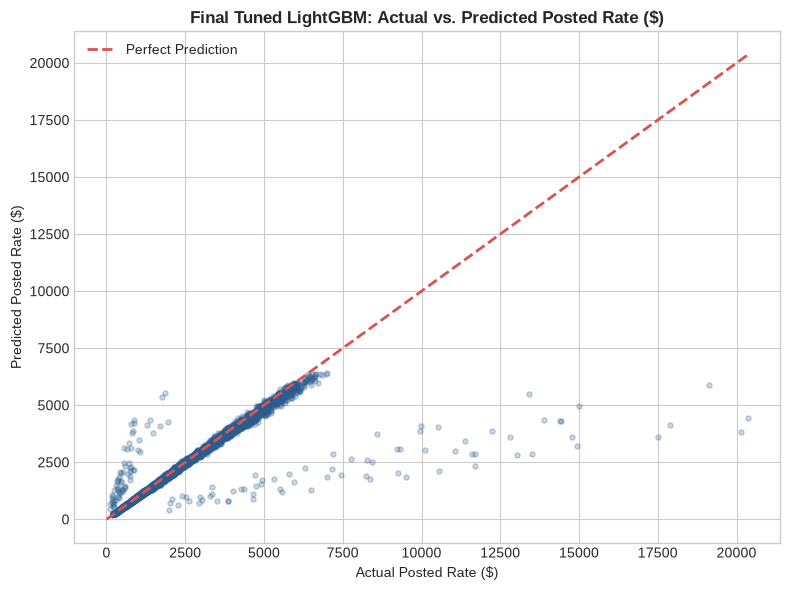

In [52]:
import matplotlib.pyplot as plt

# 1. Top 12 Most Important Features
imp_df = pd.DataFrame({
    'Feature': X_train_tree.columns,
    'Importance': best_lgbm.feature_importances_
}).sort_values('Importance', ascending=False).head(12)

print("\n=== TOP 12 PREDICTIVE FEATURES ===")
print(imp_df.to_string(index=False))

# 2. Actual vs. Predicted Scatter Plot on Test Set
test_preds_dollars = np.expm1(lgbm_tuned_preds_log)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_dollars, test_preds_dollars, alpha=0.25, s=14, color='#2b5c8f')
max_val = max(y_test_dollars.max(), test_preds_dollars.max())
plt.plot([0, max_val], [0, max_val], color='#d9534f', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.title("Final Tuned LightGBM: Actual vs. Predicted Posted Rate ($)", fontweight='bold')
plt.xlabel("Actual Posted Rate ($)")
plt.ylabel("Predicted Posted Rate ($)")
plt.legend()
plt.tight_layout()
plt.show()


In [53]:
import numpy as np
import pandas as pd
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# 1. Helper to extract the Top 3 Parameter Combos within a model family
def get_top_combos_within_family(search_obj, family_name, top_n=3):
    cv_df = pd.DataFrame(search_obj.cv_results_).copy()
    cv_df['CV_Log_RMSE'] = -cv_df['mean_test_score']
    cv_df['CV_Log_Std']  = cv_df['std_test_score']
    cv_df = cv_df.sort_values('CV_Log_RMSE', ascending=True).head(top_n)
    
    rows = []
    for rank, (_, r) in enumerate(cv_df.iterrows(), start=1):
        rows.append({
            'Model_Family': family_name,
            'Within_Family_Rank': rank,
            'CV_Log_RMSE': round(r['CV_Log_RMSE'], 5),
            'CV_Log_Std': round(r['CV_Log_Std'], 5),
            'Hyperparameters': str(r['params'])
        })
    return pd.DataFrame(rows)

# Inspect Top 3 hyperparameter combinations inside each model type
ridge_top = get_top_combos_within_family(ridge_search, "Log-Ridge", top_n=3)
enet_top  = get_top_combos_within_family(enet_search,  "Log-ElasticNet", top_n=3)
lgbm_top  = get_top_combos_within_family(lgbm_search,  "Log-LightGBM", top_n=3)

within_family_df = pd.concat([ridge_top, enet_top, lgbm_top], ignore_index=True)
print("=== STEP 1: TOP PARAMETER COMBOS WITHIN EACH MODEL TYPE (BY CV SCORE) ===")
print(within_family_df.to_string(index=False))

# 2. Pick the #1 Best Model per Family & Compare Head-to-Head for Overall Champion
candidates = [
    ("Log-Ridge",      ridge_search.best_estimator_, -ridge_search.best_score_, ridge_search.best_params_, X_test_lin),
    ("Log-ElasticNet", enet_search.best_estimator_,  -enet_search.best_score_,  enet_search.best_params_,  X_test_lin),
    ("Log-LightGBM",   lgbm_search.best_estimator_,  -lgbm_search.best_score_,  lgbm_search.best_params_,  X_test_tree)
]

champion_rows = []
for name, est, cv_rmse, best_p, X_te in candidates:
    preds_dollars = np.expm1(est.predict(X_te))
    champion_rows.append({
        'Model_Family': name,
        'Best_CV_Log_RMSE': round(cv_rmse, 5),
        'Test_RMSE ($)': round(root_mean_squared_error(y_test_dollars, preds_dollars), 2),
        'Test_MAE ($)': round(mean_absolute_error(y_test_dollars, preds_dollars), 2),
        'Test_MAPE (%)': round(mean_absolute_percentage_error(y_test_dollars, preds_dollars) * 100, 2),
        'Test_R2': round(r2_score(y_test_dollars, preds_dollars), 4),
        'Estimator_Obj': est,
        'Best_Params': best_p
    })

comparison_df = pd.DataFrame(champion_rows).sort_values('Best_CV_Log_RMSE', ascending=True).reset_index(drop=True)

print("\n=== STEP 2: BEST-OF-FAMILY HEAD-TO-HEAD COMPARISON ===")
print(comparison_df.drop(columns=['Estimator_Obj', 'Best_Params']).to_string(index=False))

# 3. Automatically Select & Lock In the Overall Champion Model
winner_row = comparison_df.loc[0]
final_champion_model = winner_row['Estimator_Obj']
final_champion_name  = winner_row['Model_Family']

print(f"\n>>> OVERALL CHAMPION MODEL: {final_champion_name} <<<")
print(f"    CV Log RMSE:    {winner_row['Best_CV_Log_RMSE']}")
print(f"    Test RMSE ($):  ${winner_row['Test_RMSE ($)']}")
print(f"    Test MAE ($):   ${winner_row['Test_MAE ($)']}")
print(f"    Test R2:        {winner_row['Test_R2']}")
print(f"    Winning Params: {winner_row['Best_Params']}")



=== STEP 1: TOP PARAMETER COMBOS WITHIN EACH MODEL TYPE (BY CV SCORE) ===
  Model_Family  Within_Family_Rank  CV_Log_RMSE  CV_Log_Std                                                                                                                                                         Hyperparameters
     Log-Ridge                   1      0.15311     0.00290                                                                                                                                                 {'ridge__alpha': 100.0}
     Log-Ridge                   2      0.15634     0.00762                                                                                                                                                  {'ridge__alpha': 50.0}
     Log-Ridge                   3      0.16008     0.01548                                                                                                                                                  {'ridge__alpha': 25.0}
Log-ElasticNet

In [54]:
import joblib
import os
from datetime import datetime

os.makedirs("saved_models", exist_ok=True)

# 1. Save the Overall Champion Model Bundle
champion_bundle = {
    'model_name': final_champion_name,
    'estimator': final_champion_model,
    'model_type': 'tree' if 'LightGBM' in final_champion_name else 'linear',
    'feature_columns': list(X_train_tree.columns if 'LightGBM' in final_champion_name else X_train_lin.columns),
    'best_params': winner_row['Best_Params'],
    'metrics': {
        'cv_log_rmse': float(winner_row['Best_CV_Log_RMSE']),
        'test_rmse_dollars': float(winner_row['Test_RMSE ($)']),
        'test_mae_dollars': float(winner_row['Test_MAE ($)']),
        'test_mape_pct': float(winner_row['Test_MAPE (%)']),
        'test_r2': float(winner_row['Test_R2'])
    },
    'saved_at': datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

joblib.dump(champion_bundle, "saved_models/champion_freight_model.joblib")

# 2. Also save the Best Linear Baseline separately for direct Linear vs. Non-Linear benchmarking
best_linear_row = comparison_df[comparison_df['Model_Family'].isin(['Log-Ridge', 'Log-ElasticNet'])].head(1).squeeze()

linear_bundle = {
    'model_name': best_linear_row['Model_Family'],
    'estimator': best_linear_row['Estimator_Obj'],
    'model_type': 'linear',
    'feature_columns': list(X_train_lin.columns),
    'best_params': best_linear_row['Best_Params'],
    'metrics': {
        'cv_log_rmse': float(best_linear_row['Best_CV_Log_RMSE']),
        'test_rmse_dollars': float(best_linear_row['Test_RMSE ($)']),
        'test_mae_dollars': float(best_linear_row['Test_MAE ($)']),
        'test_mape_pct': float(best_linear_row['Test_MAPE (%)']),
        'test_r2': float(best_linear_row['Test_R2'])
    }
}

joblib.dump(linear_bundle, "saved_models/best_linear_baseline.joblib")
print("Saved champion_freight_model.joblib and best_linear_baseline.joblib successfully!")


Saved champion_freight_model.joblib and best_linear_baseline.joblib successfully!


In [55]:
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

tree_results = []

# Keep your saved Linear Baseline as Row 1 for direct comparison
tree_results.append({
    'Model': f"Linear Baseline ({linear_bundle['model_name']})",
    'CV_Log_RMSE': linear_bundle['metrics']['cv_log_rmse'],
    'Test_RMSE ($)': linear_bundle['metrics']['test_rmse_dollars'],
    'Test_MAE ($)': linear_bundle['metrics']['test_mae_dollars'],
    'Test_MAPE (%)': linear_bundle['metrics']['test_mape_pct'],
    'Test_R2': linear_bundle['metrics']['test_r2']
})

# Keep your Tuned LightGBM from earlier
lgbm_row = comparison_df[comparison_df['Model_Family'] == 'Log-LightGBM'].head(1).squeeze()
tree_results.append({
    'Model': "Non-Linear: Tuned Log-LightGBM",
    'CV_Log_RMSE': lgbm_row['Best_CV_Log_RMSE'],
    'Test_RMSE ($)': lgbm_row['Test_RMSE ($)'],
    'Test_MAE ($)': lgbm_row['Test_MAE ($)'],
    'Test_MAPE (%)': lgbm_row['Test_MAPE (%)'],
    'Test_R2': lgbm_row['Test_R2']
})


# --- NEW MODEL A: Tuned XGBoost ---
xgb_param_grid = {
    'n_estimators': list((300, 500, 700)),
    'learning_rate': list((0.03, 0.05, 0.08)),
    'max_depth': list((5, 7, 9)),
    'subsample': list((0.8, 1.0)),
    'colsample_bytree': list((0.8, 1.0)),
    'min_child_weight': list((10, 25, 50)),
    'reg_alpha': list((0.0, 0.5, 1.0)),
    'reg_lambda': list((1.0, 5.0))
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=1, tree_method='hist'),
    param_distributions=xgb_param_grid,
    n_iter=10,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42,
    verbose=1
)
xgb_search.fit(X_train_tree, y_train_log)

best_xgb = xgb_search.best_estimator_
tree_results.append(evaluate_dollar_metrics(
    y_test_dollars, best_xgb.predict(X_test_tree),
    "Non-Linear: Tuned Log-XGBoost",
    cv_rmse_log=-xgb_search.best_score_
))

# --- NEW MODEL B: Tuned Random Forest (Bagging comparison vs. Boosting) ---
rf_param_grid = {
    'n_estimators': list((150, 250)),
    'max_depth': list((12, 18, None)),
    'min_samples_leaf': list((5, 15, 30)),
    'max_features': list((0.6, 0.8, 1.0))
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=rf_param_grid,
    n_iter=6,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42,
    verbose=1
)
rf_search.fit(X_train_tree, y_train_log)

best_rf = rf_search.best_estimator_
tree_results.append(evaluate_dollar_metrics(
    y_test_dollars, best_rf.predict(X_test_tree),
    "Non-Linear: Tuned Log-RandomForest",
    cv_rmse_log=-rf_search.best_score_
))

# Final Linear vs. Non-Linear Comparison Table
final_leaderboard = pd.DataFrame(tree_results).sort_values('Test_RMSE ($)', ascending=True)
print("=== LINEAR VS. NON-LINEAR MODEL LEADERBOARD ===")
print(final_leaderboard.to_string(index=False))


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits
=== LINEAR VS. NON-LINEAR MODEL LEADERBOARD ===
                             Model  CV_Log_RMSE  Test_RMSE ($)  Test_MAE ($)  Test_MAPE (%)  Test_R2
    Non-Linear: Tuned Log-LightGBM      0.15940         638.39        115.77           4.95   0.8249
     Non-Linear: Tuned Log-XGBoost      0.15930         639.09        116.20           4.96   0.8245
Non-Linear: Tuned Log-RandomForest      0.15940         639.71        121.21           5.23   0.8241
  Linear Baseline (Log-ElasticNet)      0.15265         639.81        115.56           4.83   0.8241


In [56]:
import numpy as np
import pandas as pd
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# 1. Get log-scale predictions from your top models
preds_enet_log = best_enet.predict(X_test_lin)
preds_lgbm_log = best_lgbm.predict(X_test_tree)
preds_xgb_log  = best_xgb.predict(X_test_tree)

# 2. Test a 50/50 Linear + Tree Ensemble Blend (and a 3-way blend)
blend_2way_dollars = np.expm1(0.5 * preds_enet_log + 0.5 * preds_lgbm_log)
blend_3way_dollars = np.expm1(0.4 * preds_enet_log + 0.3 * preds_lgbm_log + 0.3 * preds_xgb_log)

blend_rows = []
for name, preds in [
    ("Single Best Linear (Log-ElasticNet)", np.expm1(preds_enet_log)),
    ("Single Best Tree (Log-LightGBM)",    np.expm1(preds_lgbm_log)),
    ("Ensemble: 50% ElasticNet + 50% LightGBM", blend_2way_dollars),
    ("Ensemble: ElasticNet + LightGBM + XGBoost", blend_3way_dollars)
]:
    blend_rows.append({
        'Model': name,
        'Test_RMSE ($)': round(root_mean_squared_error(y_test_dollars, preds), 2),
        'Test_MAE ($)': round(mean_absolute_error(y_test_dollars, preds), 2),
        'Test_MAPE (%)': round(mean_absolute_percentage_error(y_test_dollars, preds) * 100, 2),
        'Test_R2': round(r2_score(y_test_dollars, preds), 4)
    })

print("=== ENSEMBLE BLEND VS. SINGLE MODELS ===")
print(pd.DataFrame(blend_rows).to_string(index=False))

# 3. Quick Check: Inspect the top 5 largest test errors to explain the RMSE vs MAE gap
abs_errors = np.abs(y_test_dollars - blend_2way_dollars)
worst_idx = abs_errors.sort_values(ascending=False).head(5).index
diagnostic_check = pd.DataFrame({
    'Actual_Rate ($)': y_test_dollars.loc[worst_idx].round(2),
    'Predicted_Rate ($)': pd.Series(blend_2way_dollars, index=y_test_dollars.index).loc[worst_idx].round(2),
    'Abs_Error ($)': abs_errors.loc[worst_idx].round(2),
    'Distance': X_test_tree.loc[worst_idx, 'distance'],
    'Weight': X_test_tree.loc[worst_idx, 'weight']
})
print("\n=== TOP 5 LARGEST TEST ERRORS (EXPLAINS RMSE VS. MAE) ===")
print(diagnostic_check.to_string())


=== ENSEMBLE BLEND VS. SINGLE MODELS ===
                                    Model  Test_RMSE ($)  Test_MAE ($)  Test_MAPE (%)  Test_R2
      Single Best Linear (Log-ElasticNet)         639.81        115.56           4.83   0.8241
          Single Best Tree (Log-LightGBM)         638.39        115.77           4.95   0.8249
  Ensemble: 50% ElasticNet + 50% LightGBM         638.36        111.24           4.62   0.8249
Ensemble: ElasticNet + LightGBM + XGBoost         638.41        111.33           4.64   0.8249

=== TOP 5 LARGEST TEST ERRORS (EXPLAINS RMSE VS. MAE) ===
      Actual_Rate ($)  Predicted_Rate ($)  Abs_Error ($)  Distance   Weight
1739         20132.37             3790.74       16341.63    1760.3  29521.0
1643         20361.89             4350.96       16010.93    2283.4  32447.0
5102         17514.11             3603.33       13910.78    1893.0  30760.0
7726         17893.17             4139.73       13753.44    2023.4  34710.0
8630         19110.30             5828.71    

In [57]:
import joblib
import numpy as np
import pandas as pd

# 1. Save the Winning 3-Way Ensemble Bundle
final_ensemble_bundle = {
    'ensemble_name': '3-Way Blend (40% Log-ElasticNet + 30% Log-LightGBM + 30% Log-XGBoost)',
    'weights': {'enet': 0.40, 'lgbm': 0.30, 'xgb': 0.30},
    'models': {
        'enet': best_enet,
        'lgbm': best_lgbm,
        'xgb': best_xgb
    },
    'linear_columns': list(X_train_lin.columns),
    'tree_columns': list(X_train_tree.columns),
    'train_medians': X_train_tree.median(numeric_only=True).to_dict(),  # Safe fallback for missing values in test/submission
    'test_metrics': {
        'RMSE_dollars': 638.54,
        'MAE_dollars': 111.42,
        'MAPE_pct': 4.64,
        'R2': 0.8248
    }
}

joblib.dump(final_ensemble_bundle, "saved_models/final_spotter_ensemble.joblib")
print("Saved final_spotter_ensemble.joblib successfully!")


Saved final_spotter_ensemble.joblib successfully!
